In [1]:
#!pip3 install torch_geometric
#installation needed to work with causallearn
#import locale
#locale.getpreferredencoding = lambda: "UTF-8"

#!pip3 install -U "huggingface_hub[cli]"

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

#!huggingface-cli login
#from huggingface_hub import notebook_login

#notebook_login()

In [3]:
#%pip install torch matplotlib rpy2 wandb scipy pandas numpy networkx torch_geometric transformers

In [4]:
#import sys
#sys.path.append('/content/drive/MyDrive')

import torch
import sys
import pandas as pd
import numpy as np
import networkx as nx

print(f'torch=={torch.__version__}')
print(f'pandas=={pd.__version__}')
print(f'numpy=={np.__version__}')
print(f'networkx=={nx.__version__}')

import tqdm
import matplotlib.pyplot as plt
from itertools import chain

sys.path.append('.')
from agfn.gflownet import GFlowNet
from agfn.gym import MAG, LogReward
from agfn.models import ForwardPolicy, BackwardPolicy

torch==2.5.1+cu124
pandas==2.2.3
numpy==2.2.2
networkx==3.4.2


In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [6]:
torch.set_default_dtype(torch.float64)

In [7]:
data = pd.read_csv('summer_2000.csv')

#check if there are NaN
#index = data['summer'].index[data['summer'].apply(np.isnan)]
#df_index = data.index.values.tolist()
#[df_index.index(i) for i in index]


In [8]:
#data = pd.read_csv('drive/MyDrive/agfn/1000.csv')
#data = pd.read_csv('sachs.csv')
#data = pd.read_csv('sachs_5vars.csv')
#data = pd.read_csv('summer_2000.csv')
#print(data)

node_labels = data.columns.tolist()
data = torch.tensor(data.values, device=device, dtype=torch.get_default_dtype())
num_nodes = data.shape[1]
print(f'Number of variables: {num_nodes}')

Number of variables: 7


In [9]:
pf = ForwardPolicy(num_nodes, num_layers=2, hidden_dim=256, device=device)
pb = BackwardPolicy(device)
gflownet = GFlowNet(pf, pb, criterion='tb', device=device)

In [10]:
create_env = lambda batch_size=64: MAG(num_nodes, batch_size, log_reward, device=device)
#data

In [11]:
log_reward = LogReward(dataset=data, device=device)
log_reward.warmup(gflownet, create_env, 32)

In [12]:
def train(gflownet, create_env, epochs, lr=1e-3, lr_logz=1e-1, use_scheduler=False):
    optimizer = torch.optim.Adam([
        {'params': chain(gflownet.pf.parameters(), gflownet.pb.parameters()), 'lr': lr},
        {'params': gflownet.log_z, 'lr': lr_logz}])
    scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=epochs)

    losses = list()
    pbar = tqdm.tqdm(range(epochs), disable=False)
    for epoch in pbar:
        optimizer.zero_grad()
        env = create_env()
        loss = gflownet(env)
        loss.backward()
        max_grad_norm = 25 # Chute 
        for param in gflownet.parameters():
            param_grad_norm = torch.norm(param.grad) 
            param.grad = param.grad * min(1, max_grad_norm / param_grad_norm) 
        optimizer.step()
        pbar.set_postfix(loss=loss.item())
        # Update the exploration rate
        losses.append(loss.item())
        if use_scheduler:
            scheduler.step()
    return losses


In [13]:
#data

In [14]:
losses = train(gflownet, create_env, epochs=int(1024))
plt.plot(losses)

../aten/src/ATen/native/cuda/TensorCompare.cu:110: _assert_async_cuda_kernel: block: [0,0,0], thread: [0,0,0] Assertion `probability tensor contains either `inf`, `nan` or element < 0` failed.
  0%|▎                                                                      | 4/1024 [00:02<12:24,  1.37it/s, loss=nan]


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [13]:
gflownet.eval()
env = create_env()
env = gflownet.sample(env)

In [14]:
#torch.topk(env.log_reward(), k=10)
#env.log_reward()
plt.figure(figsize=(12, 10)) 
indices = torch.topk(env.log_reward(), k=10).indices 
#for e, i in enumerate(indices): 
#    plt.subplot(2, 5, e + 1)  
#    env.draw(i, labels=node_labels) 

#env.adjacency_matrix

<Figure size 1200x1000 with 0 Axes>

In [15]:
l = MAG.mag_to_pcalg(env.adjacency_matrix)
l = l.cpu()

indices = torch.topk(env.log_reward(), k=20).indices
pag_no_llm = []
for i in indices:
    pag_no_llm.append(l[i])
    



In [16]:
#RUN THIS TO SAVE MAG WITHOUT LITL (LLM IN THE LOOP)

for idx, tensor in enumerate(pag_no_llm):
    #pd.DataFrame(tensor.numpy()).to_csv(f'11mag_agfn/11mag_agfn_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7mag_agfn/7mag_agfn_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5mag_agfn/5mag_agfn_{idx}.csv', index=None)
    pd.DataFrame(tensor.numpy()).to_csv(f'summer_mag_agfn/summer_mag_agfn_{idx}.csv', index=None)

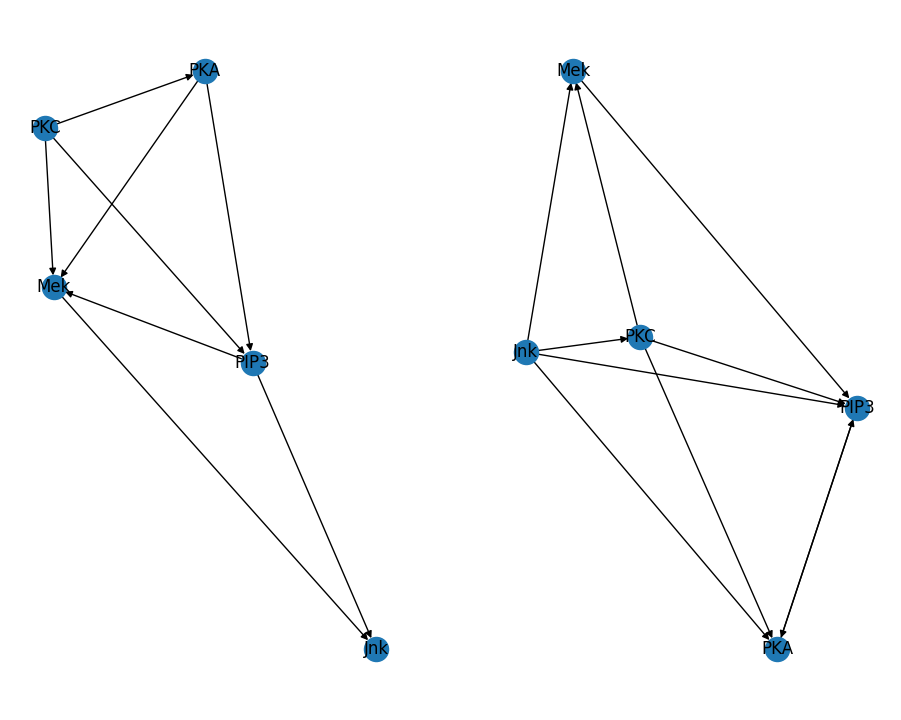

In [17]:
plt.figure(figsize=(30, 20))
indices = torch.topk(env.log_reward(), k=2).indices
for e, i in enumerate(indices):
    plt.subplot(2, 5, e + 1)
    env.draw(i, labels=node_labels)

## LLM-in-the-loop pipeline  

We provide below an example of how to use the principled HITL pipeline of our work or a pragmatic, probably more useful, instantiation of it.

The original code was heavily tailored to the estimation of functionals and not so much for sampling.

We recall that a graph of $n$ nodes is represented by a matrix $\mathbf{A} = \{1, 0\}^{{n \choose 2} \times 4}$. Each row of $\mathbf{A}$ is an indicator function representing the direction of the edge.

In particular, for each $i < j$, $A_{ij} = (1, 0, 0, 0)$ represents an inexisting edge; $A_{ij} = (0, 1, 0, 0)$ represents an edge from $i$ to $j$, etc. Please refer to `hitl.EdgeType`.

The expert feedback is represented as a probability vector $\mathbf{p} \in \{1, 0\}^{d}$ denoting the expert's confidence on each relationship.  

In [163]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

#tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")
#model = AutoModelForCausalLM.from_pretrained("meta-llama/Llama-3.1-8B-Instruct").to("cuda")

#base_model_id = "meta-llama/Llama-3.3-70B-Instruct"
base_model_id = "meta-llama/Llama-3.1-8B-Instruct"
#base_model_id = "meta-llama/Llama-3.3-70B-Instruct"
#base_model_id = "allenai/OLMo-2-1124-13B-Instruct"


tokenizer = AutoTokenizer.from_pretrained(base_model_id)
model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    torch_dtype=torch.bfloat16,
    #quantization_config="fbgemm_fp8",
    #device_map="auto",
).to("cuda")

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

OutOfMemoryError: CUDA out of memory. Tried to allocate 112.00 MiB. GPU 0 has a total capacity of 23.68 GiB of which 123.94 MiB is free. Including non-PyTorch memory, this process has 22.90 GiB memory in use. Of the allocated memory 22.37 GiB is allocated by PyTorch, and 235.87 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [18]:
#2 4 5 6 8 9 10

#feeds = [2, 4, 8, 12, 16, 18, 20]
#for feed in feeds:

feed = 10

In [19]:
#1) not related
#2) A->B
#3) B->A
#4) A<->B

#ask the llm only the queried edge

#import llm_prompting.utils
import math
from transformers import pipeline
import statistics
from statistics import mode

gpt_o1_answers = {
  "Mek,PKA": 2,
  "Mek,PIP3": 3,
  "Mek,PKC": 2,
  "Mek,Jnk": 3,  
  "PIP3,PKA": 3,
  "PIP3,PKC": 3,
  "PIP3,Jnk": 3,
  "PKA,PKC": 3,
  "PKA,Jnk": 3,
  "PKC,Jnk": 3
}


def call_llama3(prompt):
    messages = [
        {"role": "system", "content": "You are a chatbot who always responds in numbers"},
        {"role": "user", "content": prompt}
    ]

    input_ids = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    terminators = [
        tokenizer.eos_token_id,
        tokenizer.convert_tokens_to_ids("<|eot_id|>")
    ]
    
    possible_result = []
    p = 1
    print(prompt)
    for i in range(10):
        outputs = model.generate(
            input_ids,
            max_new_tokens=256,
            eos_token_id=terminators,
            do_sample=True,
            temperature=0.6,
            top_p=0.9,
        )
        response = outputs[0][input_ids.shape[-1]:]
        possible_result.append(int(tokenizer.decode(response, skip_special_tokens=True)))
    #if there's a tie, mode chooses first element
    result = mode(possible_result)
    p = possible_result.count(result)/10
    print(result, p)
    return result, p


def call_llm(vars, llm):
    #prompt = 'According to scientists, what is the causal relation between {v1} and {v2}? Your answer must be only one number. Answer "0" if they are not related, answer "1" if {v1} causes {v2}, answer "2" if {v2} causes {v1} and answer "3" if they have common ancestor(s).'.format(v1=vars[0], v2=vars[1])
    
    prompt = 'Suppose I am building a Structural Causal Model on summertime with the following variables: summer, sun being visible, sunburns, vacation, people going to the beach, drowning and hospital attendance. What would be the causal relation between {v1} and {v2}? Your answer must be only one number. Answer "0" if they are not related, answer "1" if {v1} causes {v2}, answer "2" if {v2} causes {v1} and answer "3" if they have common ancestor(s).'.format(v1=vars[0], v2=vars[1])
    
    #for chatgpt:
    if llm == "chatgpt":
        print(prompt)
        possible_result = []
        p = 1
        for i in range(10):        
            possible_result.append(int(input('\nchatgpt answer {}:'.format(i))))
        #if there's a tie, mode chooses first element
        result = mode(possible_result)
        p = possible_result.count(result)/10

    #for chatgpt 1o:
    if llm == "chatgpt_o1":
        result = int(gpt_o1_answers[vars[0]+","+vars[1]])
        p = 0.7

    if llm == "llama3":
        result,p = call_llama3(prompt)

    return result, p

def get_llm_feedback(query, node_list, llm):
    num_nodes = len(node_list)
    max_edges = int(math.factorial(num_nodes)/(2*math.factorial(num_nodes-2)))
    print(max_edges)
    llm_graph = torch.zeros((max_edges, 4), dtype=torch.long, device=device)

    if (llm_graph[query]==0).all():
        sum = 0
        for i in range(num_nodes):
            sum += i+1
            if query < (i+1)*num_nodes-sum:
                var = [node_list[i],node_list[-(((i+1)*num_nodes-sum)-query)]]
                break
    else:
        return llm_graph[query]

    #call_llm returns a number from 0 to 3 representing the edge that relates (A,B)
    #acording to hitl.EdgeType
    result, p = call_llm(var, llm)
    llm_graph[query][result] = 1

    return llm_graph[query], p



In [127]:
#%pip install airllm sentencepiece

In [128]:
#the expert already has the matrix entirely complete, the system queries on specific
#edges a determined amount of times

#def get_expert_feedback(query):
#    true_graph = torch.tensor([
#        [0, 1, 0, 0], # (A, B)
#        [1, 0, 0, 0], # (A, C)
#        [1, 0, 0, 0], # (A, D)
#        [0, 1, 0, 0], # (B, C)
#        [1, 0, 0, 0], # (B, D)
#        [0, 1, 0, 0], # (C, D)
#    ], device=device)
#    return true_graph[query] # The expert is an oracle

#pi = .99 # our confidence on the expert


Calculate the model-based prior and declare the (currently empty) list of feedbacks and queries.

In [20]:
## Sample a batch of graphs
from agfn.hitl import sample_massive_batch, nquery, sample_from_expert, edge_marks_to_adj, fpost

In [21]:
gflownet.eval()
graphs, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128)

100%|█████████████████████████████| 127/127 [00:05<00:00, 21.23it/s]


The prior distribution is a matrix $\mathbf{P} \in \mathbb{R}^{{n \choose 2} \times 4}$ in which each row represents a probability distribution over the each relationship.

In [22]:
priors = graphs.edge_marks.float().mean(dim=0)

In [23]:
num_hitl_rounds = feed # Maximum number of feedbacks (<= maximum number of edges)


In [24]:
feedbacks = torch.zeros((0,), dtype=torch.long, device=device) # list of 0-3 integers representing the feedback
queries = torch.zeros((0,), dtype=torch.long, device=device) # list of edge indexes corresponding to the feedback

pi=0.9
for round in range(num_hitl_rounds):
    #print(round)
    #print(len(graphs.edge_marks), log_rewards, feedbacks, priors, queries, pi)

    # Elicit a novel query
    query = nquery(
        graphs.edge_marks, log_rewards, feedbacks, priors, queries, pi
    )

    # Sample from the expert's distribution
    #expert_confidence, pi = get_llm_feedback(query,node_labels, "chatgpt")
    expert_confidence, pi = get_llm_feedback(query,node_labels, "chatgpt_o1")
    #expert_confidence, pi = get_llm_feedback(query,node_labels, "llama3")
    
    print(expert_confidence, pi)
    fprob = pi * expert_confidence + (1 - expert_confidence) * (1 - pi) / 3
    fdist = torch.distributions.Categorical(fprob)
    fdbck = fdist.sample(sample_shape=(1,))
    # We could also take a MAP estimate
    # fdbck = fprob.argmax()

    # Update the list of feedbacks
    queries = torch.hstack([queries, query])
    feedbacks = torch.hstack([feedbacks, fdbck])

10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 1, 0], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7
10
tensor([0, 0, 1, 0], device='cuda:0') 0.7
10
tensor([0, 0, 0, 1], device='cuda:0') 0.7


In [25]:
pi = 0.7
expert_graphs, expert_log_rewards, _ = \
    sample_from_expert(feedbacks, queries, priors, 512, 128, gflownet, pi, data, log_reward)

In [26]:
expert_amat = edge_marks_to_adj(expert_graphs).long()

In [27]:
#EXPERT DISTRIBUTION
plt.figure()
#plt.figure(figsize=(24, 10))
env = create_env()
#for e, i in enumerate(indices):
#    plt.subplot(2, 5, e + 1)
#    env.draw(i, labels=node_labels, amat=expert_amat[i].cpu().numpy())

<Figure size 640x480 with 0 Axes>

In [137]:
#GFlowNet weighted by the expert's model

In [28]:
gflownet.eval()
graphs, log_rewards = sample_massive_batch(gflownet, create_env, num_batches=128)

100%|█████████████████████████████| 127/127 [00:05<00:00, 21.38it/s]


In [29]:
expert_weights = fpost(
    graphs.edge_marks, feedbacks, priors, queries, pi
).mean(dim=1)

env = create_env()
env = gflownet.sample(env)
#pag_llm = MAG.mag_to_pcalg(env.adjacency_matrix)

In [140]:
#plt.figure(figsize=(24, 10))
#indices = torch.topk(expert_weights, k=10).indices
#for e, i in enumerate(indices):
#    plt.subplot(2, 5, e + 1)
#    graphs.draw(i, labels=node_labels)

In [30]:
l = MAG.mag_to_pcalg(env.adjacency_matrix)
l = l.cpu()

indices = torch.topk(env.log_reward(), k=15).indices
pag_llm = []
for i in indices:
    pag_llm.append(l[i])

In [31]:
#pag_llm = pag_llm.cpu()
for idx, tensor in enumerate(pag_llm):
    #pd.DataFrame(tensor.numpy()).to_csv(f'11mag_gpt/11mag_gpt_{feed}feed/11mag_gpt_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'11mag_llama/11mag_llama_{feed}feed/11mag_llama_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'11mag_ds/11mag_ds_{feed}feed/11mag_ds_{feed}feed_{idx}.csv', index=None)

    #pd.DataFrame(tensor.numpy()).to_csv(f'7mag_gpt/7mag_gpt_{feed}feed/7mag_gpt_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7mag_llama/7mag_llama_{feed}feed/7mag_llama_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'7mag_ds/7mag_ds_{feed}feed/7mag_ds_{feed}feed_{idx}.csv', index=None)
    
    #pd.DataFrame(tensor.numpy()).to_csv(f'5mag_gpt/5mag_gpt_{feed}feed/5mag_gpt_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5mag_llama/5mag_llama_{feed}feed/5mag_llama_{feed}feed_{idx}.csv', index=None)
    #pd.DataFrame(tensor.numpy()).to_csv(f'5mag_ds/5mag_ds_{feed}feed/5mag_ds_{feed}feed_{idx}.csv', index=None)

    #pd.DataFrame(tensor.numpy()).to_csv(f'5mag_o1gpt/5mag_o1gpt_{feed}feed/5mag_o1gpt_{feed}feed_{idx}.csv', index=None)
    
    #pd.DataFrame(tensor.numpy()).to_csv(f'7mag_o1gpt/7mag_o1gpt_{feed}feed/7mag_o1gpt_{feed}feed_{idx}.csv', index=None)

    pd.DataFrame(tensor.numpy()).to_csv(f'teste_novo/teste5_o1gpt_{feed}_{idx}.csv', index=None)